In [1]:
# EDA (Exploratory Data Analysis)
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Text Preprocessing

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem.snowball import SnowballStemmer

# Model Building and Classification

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# helll


from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score

# To keep notebook clean

import warnings

warnings.filterwarnings("ignore")
# to keep notebook 

import warnings 
warnings.filterwarnings("ignore")


In [2]:
df = pd.read_csv("train.csv")
df.sample(4)

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
55331,93ce32a2493e5acc,"Agreed. In addition, Mr. Inglis seems intent ...",0,0,0,0,0,0
23776,3ecef2b3be594c92,Yawn. Let's hope the arbitration can decide on...,0,0,0,0,0,0
144928,14c63e0e21ddb4e4,""")\njohnboywalton55 says """"you're a spastic!!!...",1,0,0,0,0,0
59496,9f5fd6c642f73949,"I've just noticed that, on your user page, you...",0,0,0,0,0,0


In [3]:
df.info(
)

<class 'pandas.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   id             159571 non-null  str  
 1   comment_text   159571 non-null  str  
 2   toxic          159571 non-null  int64
 3   severe_toxic   159571 non-null  int64
 4   obscene        159571 non-null  int64
 5   threat         159571 non-null  int64
 6   insult         159571 non-null  int64
 7   identity_hate  159571 non-null  int64
dtypes: int64(6), str(2)
memory usage: 72.2 MB


In [4]:
df.isnull()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
159566,False,False,False,False,False,False,False,False
159567,False,False,False,False,False,False,False,False
159568,False,False,False,False,False,False,False,False
159569,False,False,False,False,False,False,False,False


In [5]:
df.columns

Index(['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat',
       'insult', 'identity_hate'],
      dtype='str')

In [6]:
df.loc[df["toxic"] == 1, "comment_text"].iloc[0]

'COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK'

In [7]:
x = df.iloc[:,2:].sum
x

<bound method DataFrame.sum of         toxic  severe_toxic  obscene  threat  insult  identity_hate
0           0             0        0       0       0              0
1           0             0        0       0       0              0
2           0             0        0       0       0              0
3           0             0        0       0       0              0
4           0             0        0       0       0              0
...       ...           ...      ...     ...     ...            ...
159566      0             0        0       0       0              0
159567      0             0        0       0       0              0
159568      0             0        0       0       0              0
159569      0             0        0       0       0              0
159570      0             0        0       0       0              0

[159571 rows x 6 columns]>

In [8]:
print(type(x))

<class 'method'>


In [9]:
labels = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

x = df[labels].sum()
print(x)

toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
dtype: int64


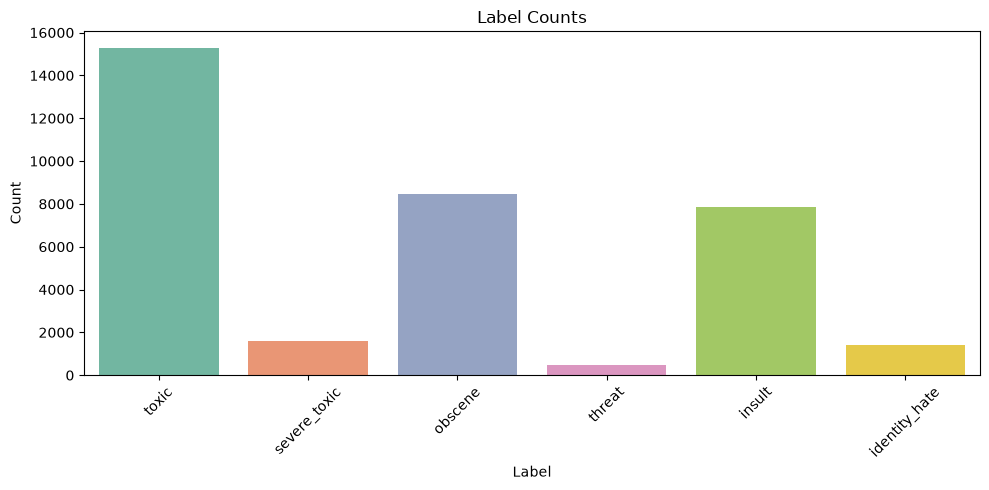

In [10]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=x.index,
    y=x.values,
    hue=x.index,
    palette="Set2",
    legend=False
)

plt.title("Label Counts")
plt.ylabel("Count")
plt.xlabel("Label")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
df.drop(columns="id",inplace=True)

In [12]:
df

,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0
...,...,...,...,...,...,...,...
159566,""":::::And for the second time of asking, when ...",0,0,0,0,0,0
159567,You should be ashamed of yourself \n\nThat is ...,0,0,0,0,0,0
159568,"Spitzer \n\nUmm, theres no actual article for ...",0,0,0,0,0,0
159569,And it looks like it was actually you who put ...,0,0,0,0,0,0


In [13]:

def remove_stopwords (text):
 no_stop_words_text = [w for w in text.split() if w.lower() not in stopwords]
 return " ".join(no_stop_words_text)

 return"".join(no_stop_words_text)

In [14]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"what's", "what is ", text)
    text = re.sub(r"\'s", " ", text)
    text = re.sub(r"\'ve", " have ", text)
    text = re.sub(r"can't", "can not ", text)
    text = re.sub(r"n't", " not ", text)
    text = re.sub(r"i'm", "i am ", text)
    text = re.sub(r"\'re", " are ", text)
    text = re.sub(r"\'d", " would ", text)
    text = re.sub(r"\'ll", " will ", text)
    text = re.sub(r"\'scuse", " excuse ", text)
    text = re.sub('\W', ' ', text)
    text = re.sub('\s+', ' ', text)
    text = text.strip(' ')
    return text

In [15]:
stemmer= SnowballStemmer("english")



def stemming(sentence):
 stemmed_sentence =""
 for word in sentence.split():
   stemmed_word = stemmer.stem(word)

   stemmed_sentence += stemmed_word+""
 stemmed_sentence = stemmed_sentence.strip()
 return stemmed_sentence

In [19]:
nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

def remove_stopwords(text):
    return " ".join(word for word in text.split() if word.lower() not in stop_words)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Aman\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [20]:
df["comment_text"] =df["comment_text"].apply(lambda x: clean_text(x))

In [21]:
df["comment_text"] =df["comment_text"].apply(lambda x: stemming(x))

In [23]:
X = df["comment_text"]
y = df.drop(columns=["comment_text"])



In [24]:
X_train, X_test,y_train,y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [25]:
def run_pipeline (pipeline, X_train, X_test,y_train,y_test):

# Traning the model

 pipeline.fit(X_train,y_train)

 #prediction from model

 predictions = pipeline.predict(X_test)

 pred_probs = pipeline.predict_proba (X_test)

# Accuracy

 print("Accuracy:", accuracy_score(y_test, predictions))

In [26]:
from sklearn.multiclass import OneVsRestClassifier
LR_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("LR_model", OneVsRestClassifier(LogisticRegression(), n_jobs=1))
])

In [27]:
run_pipeline (LR_pipeline, X_train, X_test,y_train,y_test)

Accuracy: 0.898355005483315


In [ ]:
labels = y_train.columns.values

In [34]:
import time

sentence = input("Your Comment: ")

start = time.time()
stemmed_sentence = stemming(sentence)
print("Preprocessing time:", round(time.time() - start, 3), "seconds")

start = time.time()
results = LR_pipeline.predict([stemmed_sentence])[0]
print("Prediction time:", round(time.time() - start, 3), "seconds")

for label, result in zip(labels, results):
    print(label, "---", result)

Preprocessing time: 0.007 seconds
Prediction time: 0.095 seconds
toxic --- 0
severe_toxic --- 0
obscene --- 0
threat --- 0
insult --- 0
identity_hate --- 0


In [35]:
import time

sentence = input("Your Comment: ")

start = time.time()
stemmed_sentence = stemming(sentence)
print("Preprocessing time:", round(time.time() - start, 3), "seconds")

start = time.time()
results = LR_pipeline.predict([stemmed_sentence])[0]
print("Prediction time:", round(time.time() - start, 3), "seconds")

for label, result in zip(labels, results):
    print(label, "---", result)

Preprocessing time: 0.01 seconds
Prediction time: 0.038 seconds
toxic --- 0
severe_toxic --- 0
obscene --- 0
threat --- 0
insult --- 0
identity_hate --- 0


In [40]:
import gradio as gr

# Prediction Function
def check_toxicity(comment):
    try:
        # Check if text is empty
        if not comment.strip():
            return "⚠️ **Warning:** Please enter some text to analyze."

        # Model functions (Yeh aapke pehle define hone chahiye)
        cleaned_comment = clean_text(comment)
        stemmed_comment = stemming(cleaned_comment)
        
        # Predict
        results = LR_pipeline.predict([stemmed_comment])[0]
        labels = ["Toxic", "Severe Toxic", "Obscene", "Threat", "Insult", "Identity Hate"]
        
        # Format output
        output_markdown = "### 📊 Analysis Results:\n\n"
        is_completely_safe = True
        
        for label, res in zip(labels, results):
            if res == 1:
                status = "🔴 **DETECTED** ⚠️"
                is_completely_safe = False
            else:
                status = "🟢 Safe ✅"
                
            output_markdown += f"- **{label}**: {status}\n"
            
        if is_completely_safe:
            output_markdown += "\n✨ *Good news! This comment looks completely safe and friendly.*"
            
        return output_markdown

    except Exception as e:
        return f"❌ **Error:** `{str(e)}`"

# Sabse simple aur clean UI - isme koi extra parameters nahi hain jo error dein
demo = gr.Interface(
    fn=check_toxicity,
    inputs=gr.Textbox(lines=4, placeholder="Type a message here..."),
    outputs=gr.Markdown(),
    title="🛡️ Toxic Comment Analyzer"
)

# Launch
demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7863
* Running on public URL: https://69b1d2ffd179bf9519.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
